# 横磁場イジングモデル（3. 量子回路で解く方法）

モデルの定義・今回のゴールは [01_exact_diag.ipynb](01_exact_diag.ipynb)、Jordan-Wigner変換は [02_jordan_wigner.ipynb](02_jordan_wigner.ipynb) を参照。

In [1]:
# 前の章で定義した関数は、共通パッケージ qmb から読み込む（src/qmb/ を参照）
import numpy as np
import matplotlib.pyplot as plt
from qmb.models import tfim_hamiltonian as hamiltonian, magnetization_x
from qmb.ed import ground_state, time_evolve_expectation
from qmb.operators import plus_state
from qmb.free_fermion import ground_energy as ground_energy_jw

## 3. 量子回路で解く方法（Trotter分解とVQE）

1章・2章は古典計算機で解く方法だったが、ここでは量子コンピュータ上で実際に状態$\ket{\psi(t)}$や基底状態を作り、測定によって$m_x(t)$や$E_0$を求める。

量子コンピュータで実行できるのは、1〜2量子ビットに作用する小さなユニタリ（ゲート）の積と測定だけである。そこで

- 時間発展$e^{-iHt}$は**Trotter分解**でゲートの積に近似する
- 基底エネルギーは**VQE**（変分量子固有値ソルバー）で求める

という方針をとる。以下ではQiskitで回路を組み、状態ベクトルシミュレータで計算する。

### 3-1 Trotter分解による時間発展$m_x(t)$

ハミルトニアンを2つの部分に分ける。

\begin{equation}
H = H_{ZZ} + H_X,\quad H_{ZZ} = -J\sum_j Z_jZ_{j+1},\quad H_X = -h\sum_j X_j
\end{equation}

$H_{ZZ}$と$H_X$は交換しない（$[H_{ZZ}, H_X]\neq0$）ので、$e^{-iHt}\neq e^{-iH_Xt}e^{-iH_{ZZ}t}$である。そのため$e^{-iHt}$をそのまま簡単なゲートに分解することはできない。

- **Trotter分解**

  そこで次の公式（Lie-Trotter積公式）を使う。

  \begin{equation}
  e^{-i(A+B)t} = \lim_{r\to\infty}\left(e^{-iB\,\delta t}e^{-iA\,\delta t}\right)^r,\quad \delta t = \frac{t}{r}
  \end{equation}

  これは量子回路とは関係ない数学の公式で、量子モンテカルロ法や偏微分方程式の数値解法などでも使われている。量子回路で役に立つのは、$H_{ZZ}$と$H_X$を**それぞれ単独で**指数関数にしたものがゲートで書けるからである。

- **ゲートへの変換**

  $H_{ZZ}$の中の項どうし、$H_X$の中の項どうしはそれぞれ交換するので

  \begin{equation}
  e^{-iH_{ZZ}\delta t} = \prod_j e^{iJ\delta t\,Z_jZ_{j+1}} = \prod_j R_{ZZ}(-2J\delta t),\qquad
  e^{-iH_X\delta t} = \prod_j e^{ih\delta t\,X_j} = \prod_j R_X(-2h\delta t)
  \end{equation}

  と、ちょうど分解できる。ここで$R_{ZZ}(\theta) = e^{-i\frac{\theta}{2}Z\otimes Z}$、$R_X(\theta) = e^{-i\frac{\theta}{2}X}$はQiskitの標準ゲートである。

  したがって1ステップ分の回路は「$R_{ZZ}$を隣り合うペアにかける層」と「$R_X$を全サイトにかける層」だけでできる。$R_{ZZ}$は偶数番目のボンドと奇数番目のボンドに分けると、それぞれ並列にかけられる。そのため1ステップの回路の深さはサイト数$n$によらず3層で、ゲート数は$R_{ZZ}$が$n-1$個、$R_X$が$n$個である。これを$r$回繰り返す。

- **初期状態と測定**

  初期状態$\ket{+\cdots+}$は$\ket{0\cdots0}$の全量子ビットにアダマールゲート$H$をかければ作れる。

  $m_x$を測るには、終状態の全量子ビットに再び$H$をかけて$Z$基底で測定する（$H$で$\ket{\pm}\to\ket{0},\ket{1}$と移るため）。結果のビット$b_j\in\{0,1\}$から$X_j = 1-2b_j = \pm1$が得られるので、多数回（ショット数$N_{\mathrm{shot}}$回）測定して平均をとれば$m_x(t)$の推定値になる。統計誤差は$1/\sqrt{N_{\mathrm{shot}}}$程度である。シミュレータでは状態ベクトルから期待値を直接計算できるので、以下では主にそれを使う。

### 3-2 Trotter誤差

Trotter分解は$r$が有限だと近似になる。2つの指数関数の積はBaker-Campbell-Hausdorff（BCH）公式より

\begin{equation}
e^{-iB\,\delta t}e^{-iA\,\delta t} = \exp\left[-i\delta t\left(A + B - \frac{i\delta t}{2}[B, A] + O(\delta t^2)\right)\right]
\end{equation}

となるので、1ステップごとに$O(\delta t^2)$の誤差が出る。$r$ステップでは誤差が積み重なり

\begin{equation}
\left\| e^{-iHt} - \left(e^{-iH_X\delta t}e^{-iH_{ZZ}\delta t}\right)^r \right\| \le \frac{t^2}{2r}\left\|[H_{ZZ}, H_X]\right\| = O\left(\frac{t^2}{r}\right)
\end{equation}

となる（**1次のTrotter分解**）。誤差を$\epsilon$以下にするには$r\sim t^2/\epsilon$ステップ、つまり誤差の逆数に比例するゲート数が必要になる。

両側を半分ずつにした**2次のTrotter分解**（鈴木分解）

\begin{equation}
e^{-iH\delta t} \approx e^{-iH_X\delta t/2}\,e^{-iH_{ZZ}\delta t}\,e^{-iH_X\delta t/2}
\end{equation}

では$[B,A]$の項が打ち消し合い、誤差は$O(t^3/r^2)$に改善する。1ステップあたりのゲート数はほとんど変わらない。

> **今回の問題の特殊な事情**
>
> 2次の分解を$r$回繰り返すと、隣り合う$e^{-iH_X\delta t/2}$がくっついて
>
> \begin{equation}
> \left(e^{-iH_X\frac{\delta t}{2}}e^{-iH_{ZZ}\delta t}e^{-iH_X\frac{\delta t}{2}}\right)^r
> = e^{iH_X\frac{\delta t}{2}}\left(e^{-iH_X\delta t}e^{-iH_{ZZ}\delta t}\right)^r e^{-iH_X\frac{\delta t}{2}}
> \end{equation}
>
> と、1次の分解の両側に$e^{\pm iH_X\delta t/2}$をつけた形になる。初期状態$\ket{+\cdots+}$は$H_X$の固有状態なので右端は位相がつくだけであり、左端の$e^{iH_X\delta t/2}$は$M_x$と交換する。したがって**$m_x(t)$は1次と2次で完全に同じ値になり、どちらも誤差は$O(\delta t^2)$**である。状態そのもの（忠実度）は1次と2次で異なるが、今回測る$m_x$に限っては1次の分解でも2次の精度が出る。

### 3-3 VQEによる基底エネルギー$E_0$

- **変分原理**

  任意の規格化された状態$\ket{\psi}$について

  \begin{equation}
  E(\psi) = \bra{\psi}H\ket{\psi} \ge E_0
  \end{equation}

  が成り立ち、等号は$\ket{\psi}$が基底状態のときに限る。そこでパラメータ$\boldsymbol{\theta}$を持つ量子回路で状態$\ket{\psi(\boldsymbol{\theta})}$を作り、$E(\boldsymbol{\theta})$を最小化すれば$E_0$に近づく。これがVQEである。

- **アルゴリズムの流れ**

  1. 量子コンピュータで$\ket{\psi(\boldsymbol{\theta})}$を作り、$E(\boldsymbol{\theta})$を測定する
  2. 古典コンピュータの最適化手法で$\boldsymbol{\theta}$を更新する
  3. $E(\boldsymbol{\theta})$が収束するまで1, 2を繰り返す

  $E$の測定では、$Z_jZ_{j+1}$の項は$Z$基底で、$X_j$の項は$X$基底で測る。このように2種類の測定をすればすべての項が求まる。

- **アンザッツ（回路の形）**

  回路の形をどう選ぶかが重要である。今回は3-1のTrotterの1ステップと同じ形で、回転角を自由なパラメータにしたもの（**Hamiltonian Variational Ansatz, HVA**）を使う。

  \begin{equation}
  \ket{\psi(\boldsymbol{\beta}, \boldsymbol{\gamma})} = \prod_{l=1}^{p} e^{-i\gamma_l H_X}e^{-i\beta_l H_{ZZ}}\ket{+\cdots+}
  \end{equation}

  $p$は層の数で、パラメータは$2p$個である。$\ket{+\cdots+}$は$J=0$のときの基底状態なので、そこから$H_{ZZ}$と$H_X$を交互にかけて本当の基底状態に近づけていくイメージである（QAOAと同じ構造）。

  ただし開放境界条件では端があるため、サイトごとに最適な回転角が異なる。そこで各ゲートに別々のパラメータを持たせたもの

  \begin{equation}
  \ket{\psi(\boldsymbol{\theta})} = \prod_{l=1}^{p}\left(\prod_j e^{ih\gamma_{l,j}X_j}\prod_j e^{iJ\beta_{l,j}Z_jZ_{j+1}}\right)\ket{+\cdots+}
  \end{equation}

  も試す（パラメータは$p(2n-1)$個）。前者を「一様なHVA」、後者を「局所的なHVA」と呼ぶことにする。

> 周期境界条件では一様なHVAでも$p=n/2$層で厳密な基底状態に到達できることが知られている（W. W. Ho and T. H. Hsieh, SciPost Phys. 6, 029 (2019)）。

### 3-4 具体例を考えてみる

1-3と同じく$n=2$（開放境界）の場合を手で計算する。

- **有効1スピンへの帰着**

  1-3で見たように、$\ket{++}$から出発すると状態は$\{\ket{\phi_+}, \ket{\psi_+}\}$の2次元部分空間から出ない。この部分空間で

  $$
  Z_1Z_2\ket{\phi_+} = \ket{\phi_+},\quad Z_1Z_2\ket{\psi_+} = -\ket{\psi_+},\quad (X_1+X_2)\ket{\phi_+} = 2\ket{\psi_+}
  $$

  なので、$\ket{\phi_+}$を$\ket{0}$、$\ket{\psi_+}$を$\ket{1}$とみなした1つの有効スピンのPauli行列$\sigma$を使うと

  $$
  H_{ZZ} = -J\sigma_z,\quad H_X = -2h\sigma_x,\quad M_x = \sigma_x,\quad \ket{++} = \frac{\ket{\phi_+}+\ket{\psi_+}}{\sqrt{2}} = \ket{+}_{\mathrm{eff}}
  $$

  と書ける。つまり$n=2$の問題は、磁場$(2h, 0, J)$中の1スピンの問題と同じである。

- **Trotter分解の誤差**

  1次のTrotter分解の1ステップ$e^{-iH_X\delta t}e^{-iH_{ZZ}\delta t}$をBCH公式で1つの指数関数にまとめると、$[\sigma_x, \sigma_z] = -2i\sigma_y$より

  $$
  \begin{aligned}
  \tilde{H}
  &= H_{ZZ} + H_X - \frac{i\delta t}{2}[H_X, H_{ZZ}] + O(\delta t^2) \\
  &= -J\sigma_z - 2h\sigma_x - 2Jh\,\delta t\,\sigma_y + O(\delta t^2)
  \end{aligned}
  $$

  となる。Trotter分解の影響は、$O(\delta t)$の大きさの**$y$方向の余分な磁場**として現れる。

  スピンは磁場の方向$\hat{\boldsymbol{n}}$のまわりを角速度$2\tilde{\Omega}$（$\tilde{\Omega}$は磁場の大きさ）で歳差運動する。$x$方向を向いた初期状態から出発すると、回転の公式より

  $$
  m_x(t) = n_x^2 + (1 - n_x^2)\cos(2\tilde{\Omega}t)
  $$

  となり、$m_x$は$n_x^2$と$\tilde{\Omega}$だけで決まる（$\hat{\boldsymbol{n}}\times\hat{\boldsymbol{x}}$の$x$成分が0であるため）。$y$方向の磁場$2Jh\delta t$が加わっても

  $$
  \tilde{\Omega}^2 = J^2 + 4h^2 + O(\delta t^2),\quad n_x^2 = \frac{4h^2}{\tilde{\Omega}^2}
  $$

  と、どちらも$O(\delta t^2)$しか変わらない。よって$m_x(t)$の誤差は$O(\delta t^2)$であり、3-2で述べた「1次の分解でも$m_x$は2次の精度」が$n=2$で具体的に確かめられる。また$\delta t\to0$では$n_x^2 = 4h^2/(J^2+4h^2)$、$\tilde{\Omega} = \sqrt{J^2+4h^2}$となり、1-3の結果に戻る。

- **VQEによる基底エネルギー**

  一様なHVAで$p=1$とする。$e^{-i\beta H_{ZZ}} = e^{i\beta J\sigma_z}$は有効スピンを$z$軸まわりに$-2J\beta$回転させ、$e^{-i\gamma H_X} = e^{2i\gamma h\sigma_x}$は$x$軸まわりに$-4h\gamma$回転させる。$x$方向を向いた初期状態のBloch ベクトル$(1, 0, 0)$は

  $$
  (1,0,0) \to (\cos 2J\beta,\ -\sin 2J\beta,\ 0) \to (\cos 2J\beta,\ -\sin 2J\beta\cos 4h\gamma,\ \sin 2J\beta\sin 4h\gamma)
  $$

  と移る。エネルギーは$E = \langle H_{ZZ} + H_X\rangle = -J\langle\sigma_z\rangle - 2h\langle\sigma_x\rangle$なので

  $$
  E(\beta, \gamma) = -J\sin(2J\beta)\sin(4h\gamma) - 2h\cos(2J\beta)
  $$

  である。まず$\sin(4h\gamma) = 1$、すなわち$\gamma = \frac{\pi}{8h}$とすると$E = -J\sin(2J\beta) - 2h\cos(2J\beta)$となる。これを$\beta$について最小化すると、$\tan(2J\beta) = \frac{J}{2h}$のとき

  $$
  E_{\min} = -\sqrt{J^2+4h^2} = E_0
  $$

  となり、$n=2$では$p=1$で厳密な基底エネルギーが得られる。$J=1, h=0.5$では最適なパラメータは$\beta = \frac{\pi}{8},\ \gamma = \frac{\pi}{4}$である。

### 3-5 コードで確かめる

Qiskitで回路を組んで計算する。Qiskitは量子ビットの並びが1章の`np.kron`と逆順だが、今回扱う$H$と$M_x$は左右反転で変わらないので、そのまま比較できる。

In [2]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
from scipy.optimize import minimize

# ハミルトニアンと M_x を Pauli 演算子の和として表す（開放境界）
def tfim_op(n, J, h):
    zz = [("ZZ", [j, j + 1], -J) for j in range(n - 1)]
    x = [("X", [j], -h) for j in range(n)]
    return SparsePauliOp.from_sparse_list(zz + x, num_qubits=n)

def mx_op(n):
    return SparsePauliOp.from_sparse_list([("X", [j], 1 / n) for j in range(n)], num_qubits=n)

# 初期状態 |+...+> を作る回路
def plus_circuit(n):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    return qc

# Trotter分解の1ステップ
def trotter_step(n, J, h, dt, order=1):
    """order=1: e^{-iH_X dt} e^{-iH_ZZ dt}
    order=2: e^{-iH_X dt/2} e^{-iH_ZZ dt} e^{-iH_X dt/2}"""
    qc = QuantumCircuit(n)

    def zz_layer(tau):   # e^{-iH_ZZ tau} = Π R_ZZ(-2J tau)
        for start in (0, 1):   # 偶数番目のボンド → 奇数番目のボンド
            for j in range(start, n - 1, 2):
                qc.rzz(-2 * J * tau, j, j + 1)

    def x_layer(tau):    # e^{-iH_X tau} = Π R_X(-2h tau)
        for j in range(n):
            qc.rx(-2 * h * tau, j)

    if order == 1:
        zz_layer(dt)
        x_layer(dt)
    else:
        x_layer(dt / 2)
        zz_layer(dt)
        x_layer(dt / 2)
    return qc

# Trotter分解で m_x(t) を計算する（t = 0, δt, 2δt, ..., t_max）
def mx_trotter(n, J, h, t_max, r, order=1):
    dt = t_max / r
    step = trotter_step(n, J, h, dt, order)
    sv = Statevector(plus_circuit(n))
    M = mx_op(n)
    out = [sv.expectation_value(M).real]
    for _ in range(r):
        sv = sv.evolve(step)   # 1ステップ分の回路をかける
        out.append(sv.expectation_value(M).real)
    return np.linspace(0, t_max, r + 1), np.array(out)

# 1ステップの回路（n=4）
print(trotter_step(4, 1.0, 0.5, 0.1).draw())

                ┌──────────┐            
q_0: ─■─────────┤ Rx(-0.1) ├────────────
      │ZZ(-0.2) └──────────┘┌──────────┐
q_1: ─■──────────■──────────┤ Rx(-0.1) ├
                 │ZZ(-0.2)  ├──────────┤
q_2: ─■──────────■──────────┤ Rx(-0.1) ├
      │ZZ(-0.2) ┌──────────┐└──────────┘
q_3: ─■─────────┤ Rx(-0.1) ├────────────
                └──────────┘            


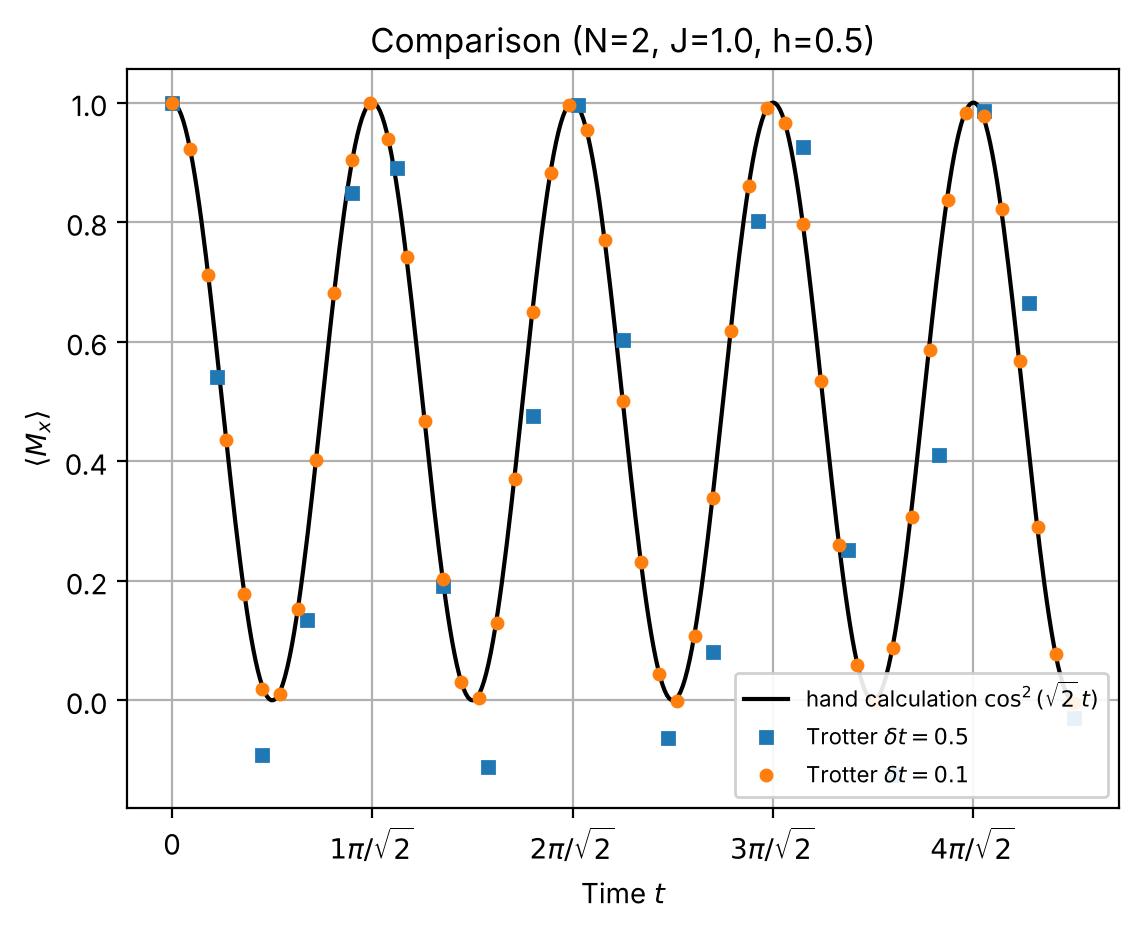

In [3]:
# 例: N=2, J=1, h=0.5（1-4と同じ条件）
N = 2
J = 1.0
h = 0.5
t_max = 10

ts_fine = np.linspace(0, t_max, 400)
T = np.pi / np.sqrt(2)   # 周期
plt.plot(ts_fine, np.cos(np.sqrt(2) * ts_fine)**2, "k-", label=r"hand calculation $\cos^2(\sqrt{2}\,t)$")
for r, mk in [(20, "s"), (100, "o")]:
    ts_r, mx_r = mx_trotter(N, J, h, t_max, r)
    every = max(1, r // 50)
    plt.plot(ts_r[::every], mx_r[::every], mk, ms=4, label=rf"Trotter $\delta t={t_max / r}$")
plt.xticks([k * T for k in range(5)], ["0"] + [rf"${k}\pi/\sqrt{{2}}$" for k in range(1, 5)])
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend(loc="lower right", fontsize=8, framealpha=0.9)
plt.grid()
plt.show()

$\delta t = 0.1$では手計算とよく一致し、$\delta t = 0.5$では振動の周期と振幅が少しずれている。これが3-4で見たTrotter誤差である。

次に$n=10$で厳密対角化と比較する。

δt = 0.50: m_x(t) の最大誤差 = 5.30e-01


δt = 0.10: m_x(t) の最大誤差 = 2.09e-02


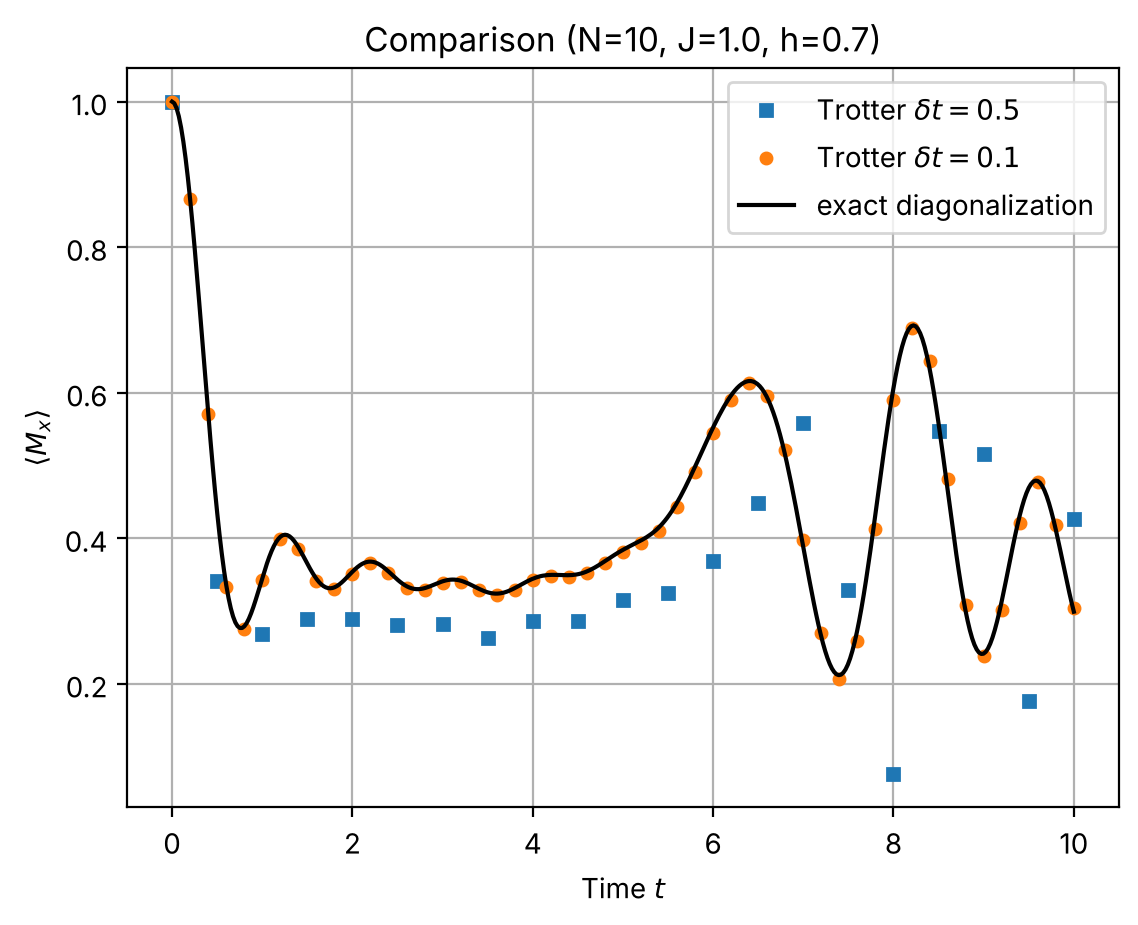

In [4]:
N = 10
J = 1.0
h = 0.7
t_max = 10

H = hamiltonian(N, J, h, pbc=False)
for r, mk in [(20, "s"), (100, "o")]:
    ts_r, mx_r = mx_trotter(N, J, h, t_max, r)
    mx_ex = time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts_r)
    print(f"δt = {t_max / r:.2f}: m_x(t) の最大誤差 = {np.max(np.abs(mx_r - mx_ex)):.2e}")
    every = max(1, r // 50)
    plt.plot(ts_r[::every], mx_r[::every], mk, ms=4, label=rf"Trotter $\delta t={t_max / r}$")

ts = np.linspace(0, t_max, 400)
plt.plot(ts, time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts), "k-", label="exact diagonalization")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Comparison (N={N}, J={J}, h={h})")
plt.legend()
plt.grid()
plt.show()

$\delta t = 0.1$では厳密対角化とよく一致するが、$\delta t = 0.5$では$n=2$のときより大きくずれる。サイト数が増えると交換しない項の組が増え、$[H_{ZZ}, H_X]$が大きくなるためである。

次に、ステップ数$r$を変えて誤差がどう縮むかを調べる。3-2の議論が正しければ、$m_x$の誤差は1次でも2次でも同じで、$r^{-2}$に比例するはずである。比較のため、状態そのものの誤差（不忠実度$1-|\bra{\psi_{\mathrm{exact}}}\ket{\psi_{\mathrm{Trotter}}}|^2$）も計算する。

1次: m_x の誤差 = [2.56479464e-01 6.15631788e-02 1.55086024e-02 3.85476272e-03
 9.63141674e-04 2.40753772e-04]


2次: m_x の誤差 = [2.56479464e-01 6.15631788e-02 1.55086024e-02 3.85476272e-03
 9.63141674e-04 2.40753772e-04]


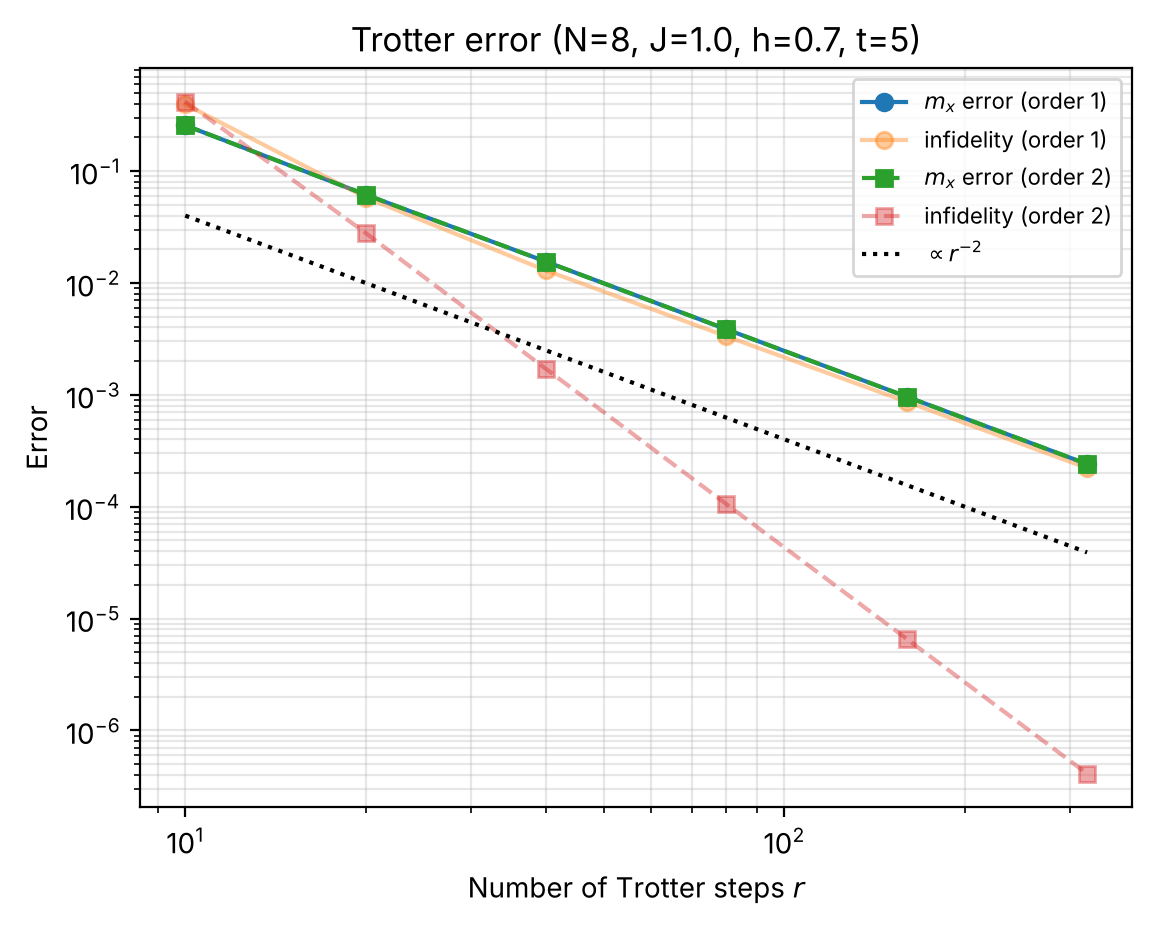

In [5]:
N = 8
J = 1.0
h = 0.7
t_max = 5
H = hamiltonian(N, J, h, pbc=False)
rs = np.array([10, 20, 40, 80, 160, 320])

# 厳密な終状態 e^{-iHt}|+...+>（Qiskitの並び順で計算）
w, v = np.linalg.eigh(tfim_op(N, J, h).to_matrix())
psi_init = Statevector(plus_circuit(N)).data
psi_exact = v @ (np.exp(-1j * w * t_max) * (v.conj().T @ psi_init))

for order, mk in [(1, "o-"), (2, "s--")]:
    mx_err, infid = [], []
    for r in rs:
        ts_r, mx_r = mx_trotter(N, J, h, t_max, r, order)
        mx_ex = time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts_r)
        mx_err.append(np.max(np.abs(mx_r - mx_ex)))
        sv = Statevector(plus_circuit(N))
        step = trotter_step(N, J, h, t_max / r, order)
        for _ in range(r):
            sv = sv.evolve(step)
        infid.append(1 - abs(np.vdot(psi_exact, sv.data))**2)
    plt.loglog(rs, mx_err, mk, label=rf"$m_x$ error (order {order})")
    plt.loglog(rs, infid, mk, alpha=0.4, label=f"infidelity (order {order})")
    print(f"{order}次: m_x の誤差 = {np.array(mx_err)}")

plt.loglog(rs, 4 / rs**2, "k:", label=r"$\propto r^{-2}$")
plt.xlabel("Number of Trotter steps $r$")
plt.ylabel("Error")
plt.title(f"Trotter error (N={N}, J={J}, h={h}, t={t_max})")
plt.legend(fontsize=8)
plt.grid(which="both", alpha=0.3)
plt.show()

$m_x$の誤差は1次と2次で完全に一致し、どちらも$r^{-2}$に比例している。一方、状態の不忠実度は2次の方が速く小さくなる（不忠実度は状態の誤差の2乗程度なので、1次では$r^{-2}$、2次では$r^{-4}$）。

最後に、実際の量子コンピュータと同じように**測定のサンプリング**で$m_x$を推定してみる。$H$ゲートをかけて$Z$基底で測定し、$X_j = 1-2b_j$の平均をとる。

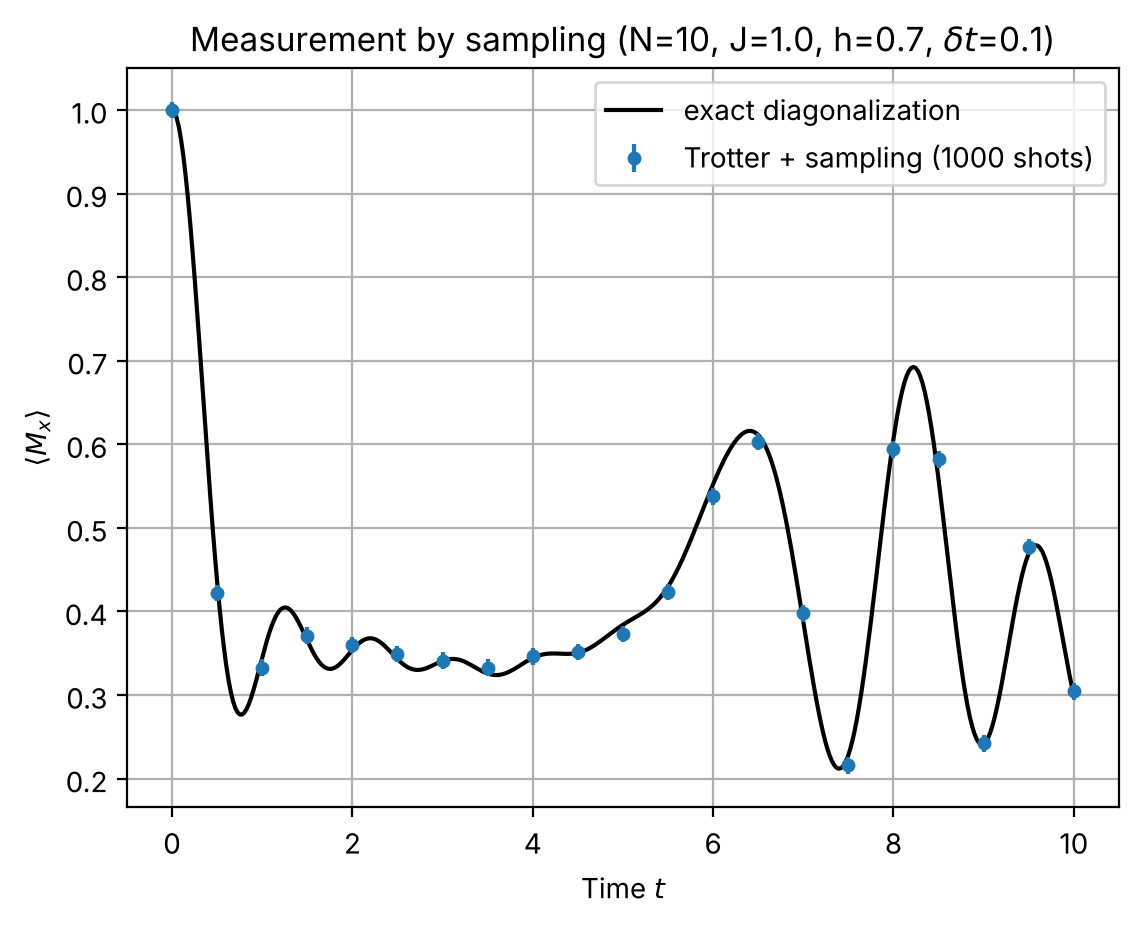

In [6]:
N = 10
J = 1.0
h = 0.7
t_max = 10
r = 100
shots = 1000

dt = t_max / r
step = trotter_step(N, J, h, dt)
had = QuantumCircuit(N)
had.h(range(N))   # X基底での測定のためのアダマールゲート

sv = Statevector(plus_circuit(N))
ts_shot, mx_shot = [], []
for k in range(r + 1):
    if k % 5 == 0:
        counts = sv.evolve(had).sample_counts(shots)   # Z基底で shots 回測定
        # ビット列の各ビット b_j から X_j = 1 - 2 b_j を計算して平均
        mx_est = sum(cnt * np.mean([1 - 2 * int(b) for b in bits]) for bits, cnt in counts.items()) / shots
        ts_shot.append(k * dt)
        mx_shot.append(mx_est)
    sv = sv.evolve(step)

ts = np.linspace(0, t_max, 400)
H = hamiltonian(N, J, h, pbc=False)
plt.plot(ts, time_evolve_expectation(H, plus_state(N), magnetization_x(N), ts), "k-", label="exact diagonalization")
plt.errorbar(ts_shot, mx_shot, yerr=1 / np.sqrt(shots * N), fmt="o", ms=4, label=f"Trotter + sampling ({shots} shots)")
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Measurement by sampling (N={N}, J={J}, h={h}, $\\delta t$={dt})")
plt.legend()
plt.grid()
plt.show()

有限回の測定による統計的なばらつきはあるが、厳密な値を再現している（エラーバーは統計誤差の目安$1/\sqrt{N_{\mathrm{shot}}\,n}$）。

続いてVQEで基底エネルギーを求める。まず$n=2$で、3-4の手計算と比較する。

In [7]:
# Hamiltonian Variational Ansatz
def hva_circuit(n, J, h, p, local=False):
    """e^{-iγ H_X} e^{-iβ H_ZZ} を p 層重ねた回路。
    local=False: 各層で β, γ を全サイト共通にする（パラメータ 2p 個）
    local=True : ゲートごとに別のパラメータにする（パラメータ p(2n-1) 個）"""
    nb, ns = (n - 1, n) if local else (1, 1)
    theta = ParameterVector("θ", p * (nb + ns))
    qc = plus_circuit(n)
    k = 0
    for _ in range(p):
        beta = theta[k:k + nb]; k += nb
        gamma = theta[k:k + ns]; k += ns
        for start in (0, 1):
            for j in range(start, n - 1, 2):
                qc.rzz(-2 * J * beta[j if local else 0], j, j + 1)
        for j in range(n):
            qc.rx(-2 * h * gamma[j if local else 0], j)
    return qc

# エネルギー期待値 E(θ)
def energy(qc, H_op, params):
    return Statevector(qc.assign_parameters(params)).expectation_value(H_op).real

# VQE（層を1つずつ増やし、前の層の最適値を初期値に使う）
def vqe(n, J, h, p_max, local=False):
    H_op = tfim_op(n, J, h)
    n_per_layer = (2 * n - 1) if local else 2
    params = np.array([])
    energies = []
    for p in range(1, p_max + 1):
        qc = hva_circuit(n, J, h, p, local)
        x0 = np.concatenate([params, np.full(n_per_layer, 0.01)])
        res = minimize(lambda x: energy(qc, H_op, x), x0, method="BFGS")
        params = res.x
        energies.append(res.fun)
    return np.array(energies), params

# 例: N=2, J=1, h=0.5, p=1
N = 2
J = 1.0
h = 0.5
E_vqe, params = vqe(N, J, h, p_max=1)
qc = hva_circuit(N, J, h, p=1)
print(qc.draw())
print(f"VQE で得たパラメータ   β = {params[0]:.6f}, γ = {params[1]:.6f}")
print(f"手計算の最適パラメータ β = π/8 = {np.pi / 8:.6f}, γ = π/4 = {np.pi / 4:.6f}")
print(f"E(π/8, π/4)       = {energy(qc, tfim_op(N, J, h), [np.pi / 8, np.pi / 4]):.6f}")
print(f"基底エネルギー E0 (VQE)  = {E_vqe[-1]:.6f}")
print(f"基底エネルギー E0 (厳密) = {-np.sqrt(J**2 + 4 * h**2):.6f}")

     ┌───┐                ┌───────────┐
q_0: ┤ H ├─■──────────────┤ Rx(-θ[1]) ├
     ├───┤ │ZZ((-2)*θ[0]) ├───────────┤
q_1: ┤ H ├─■──────────────┤ Rx(-θ[1]) ├
     └───┘                └───────────┘
VQE で得たパラメータ   β = 0.392699, γ = 0.785398
手計算の最適パラメータ β = π/8 = 0.392699, γ = π/4 = 0.785398
E(π/8, π/4)       = -1.414214
基底エネルギー E0 (VQE)  = -1.414214
基底エネルギー E0 (厳密) = -1.414214


$p=1$で厳密な基底エネルギーが得られ、最適なパラメータも手計算と一致した。

次に$n=6$で、層の数$p$を増やしたときの収束を調べる。厳密な$E_0$は2章のJW変換の結果を使う。

E0 (JW) = -6.0776390824


uniform HVA  p=1: E = -5.5474120677  相対誤差 = 8.7e-02
uniform HVA  p=2: E = -5.8385839971  相対誤差 = 3.9e-02
uniform HVA  p=3: E = -5.9585924457  相対誤差 = 2.0e-02
uniform HVA  p=4: E = -6.0264931431  相対誤差 = 8.4e-03


local HVA    p=1: E = -5.5779693855  相対誤差 = 8.2e-02
local HVA    p=2: E = -5.9083229015  相対誤差 = 2.8e-02
local HVA    p=3: E = -6.0776382898  相対誤差 = 1.3e-07
local HVA    p=4: E = -6.0776382871  相対誤差 = 1.3e-07


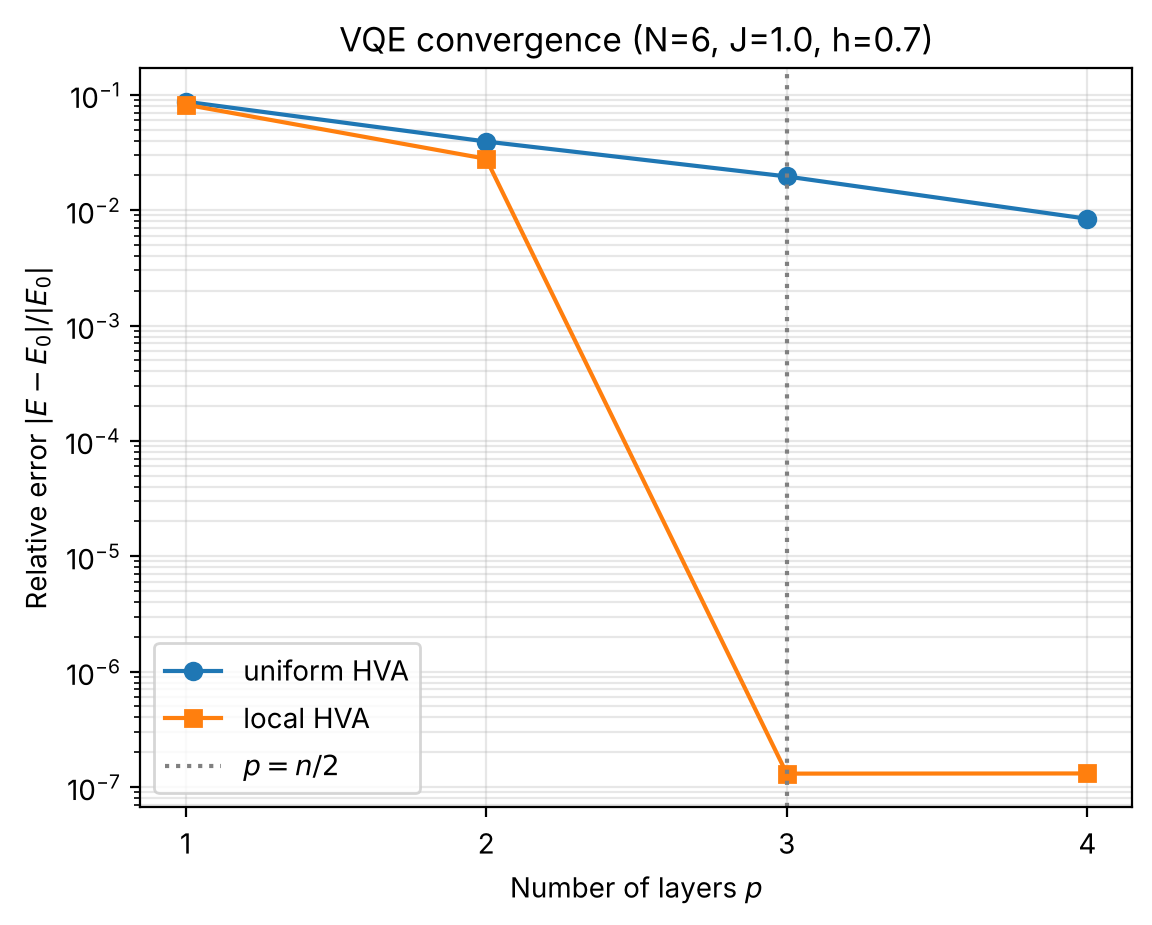

In [8]:
N = 6
J = 1.0
h = 0.7
p_max = 4
E0_exact = ground_energy_jw(N, J, h)
print(f"E0 (JW) = {E0_exact:.10f}")

ps = np.arange(1, p_max + 1)
for local, mk, name in [(False, "o-", "uniform HVA"), (True, "s-", "local HVA")]:
    E_vqe, _ = vqe(N, J, h, p_max, local)
    rel_err = np.abs(E_vqe - E0_exact) / np.abs(E0_exact)
    for p, E, err in zip(ps, E_vqe, rel_err):
        print(f"{name:12s} p={p}: E = {E:.10f}  相対誤差 = {err:.1e}")
    plt.semilogy(ps, np.maximum(rel_err, 1e-16), mk, label=name)

plt.axvline(N / 2, color="gray", ls=":", label=r"$p = n/2$")
plt.xticks(ps)
plt.xlabel("Number of layers $p$")
plt.ylabel(r"Relative error $|E - E_0| / |E_0|$")
plt.title(f"VQE convergence (N={N}, J={J}, h={h})")
plt.legend()
plt.grid(which="both", alpha=0.3)
plt.show()

一様なHVAは$p$を増やすとゆっくり近づくが、なかなか厳密値に届かない。一方、局所的なHVAは$p=3=n/2$層で一気に厳密値（相対誤差は最適化の精度程度）に到達する。

$p=n/2$という数には理由がある。1層の回路は隣のサイトとしか相関を作れないので、$p$層では距離$2p$程度までしか相関が届かない。基底状態は鎖全体にわたる相関を持つので、鎖の端から端（長さ$n$）まで情報が届く$p\approx n/2$層が必要になる。

## まとめ

| | 厳密対角化 | Jordan-Wigner変換 | 量子回路（Trotter分解・VQE） |
|---|---|---|---|
| 扱う行列・回路 | $2^n\times2^n$行列 | $2n\times2n$行列 | $n$量子ビットの回路 |
| 計算コスト | $O(2^{3n})$ | $O(n^3)$ | ゲート数は時間発展が$O(nr)$、VQEが$O(np)$ |
| 精度 | 厳密 | 厳密 | Trotter誤差・VQEの変分誤差・測定の統計誤差がある |
| 使える範囲 | 一般のハミルトニアン（小さい$n$のみ） | 2次形式になるモデルのみ | 一般のハミルトニアン |

横磁場イジングモデルはJordan-Wigner変換で厳密に解ける特別なモデルなので、古典計算機でも大きな$n$まで計算できる。しかし縦磁場を加えるなどして2次形式でなくなると、古典計算機では厳密対角化しか使えず、$n$が大きくなると計算できなくなる。量子回路による方法はそのような一般のハミルトニアンにもそのまま使えることが利点である（ただし今回のように古典計算機で量子回路をシミュレーションする場合は、状態ベクトルが$2^n$次元になるので厳密対角化と同じく大きな$n$は扱えない）。

---
**前へ**: [2. Jordan-Wigner変換](02_jordan_wigner.ipynb)